In [1]:
from qiskit.circuit import CircuitInstruction
from qiskit.circuit.library import XGate
from qiskit_qec.circuits.surface_code import SurfaceCodeCircuit

# Initialize code and extract a specific logical circuit
code = SurfaceCodeCircuit(d=3, T=3, basis="z")
circuit = code.circuit["0"]

print(f"Total gate count is now: {len(circuit.data)}")

Total gate count is now: 145


In [2]:
from collections import defaultdict

# 1. Map operations to each physical qubit index as tuples
qubit_timelines = defaultdict(list)

for index, inst in enumerate(circuit.data):
    op_name = inst.operation.name
    qubit_indices = [circuit.find_bit(q).index for q in inst.qubits]
    
    for q_idx in qubit_indices:
        # Append as a clean (index, gate_type) tuple
        qubit_timelines[q_idx].append((index, op_name))

# 2. Print the clean lists for each qubit
print("=== TUPLE TIMELINES BY QUBIT ===")
for q_idx in sorted(qubit_timelines.keys()):
    role = "Data" if q_idx < 9 else "Ancilla"
    print(f"\n🔹 Qubit {q_idx} ({role}):")
    print(f"  {qubit_timelines[q_idx]}")


=== TUPLE TIMELINES BY QUBIT ===

🔹 Qubit 0 (Data):
  [(7, 'cx'), (16, 'cx'), (55, 'cx'), (64, 'cx'), (103, 'cx'), (112, 'cx'), (136, 'measure')]

🔹 Qubit 1 (Data):
  [(4, 'cx'), (13, 'cx'), (19, 'cx'), (52, 'cx'), (61, 'cx'), (67, 'cx'), (100, 'cx'), (109, 'cx'), (115, 'cx'), (137, 'measure')]

🔹 Qubit 2 (Data):
  [(17, 'cx'), (25, 'cx'), (65, 'cx'), (73, 'cx'), (113, 'cx'), (121, 'cx'), (138, 'measure')]

🔹 Qubit 3 (Data):
  [(5, 'cx'), (20, 'cx'), (22, 'cx'), (53, 'cx'), (68, 'cx'), (70, 'cx'), (101, 'cx'), (116, 'cx'), (118, 'cx'), (139, 'measure')]

🔹 Qubit 4 (Data):
  [(8, 'cx'), (10, 'cx'), (18, 'cx'), (26, 'cx'), (56, 'cx'), (58, 'cx'), (66, 'cx'), (74, 'cx'), (104, 'cx'), (106, 'cx'), (114, 'cx'), (122, 'cx'), (140, 'measure')]

🔹 Qubit 5 (Data):
  [(6, 'cx'), (14, 'cx'), (23, 'cx'), (54, 'cx'), (62, 'cx'), (71, 'cx'), (102, 'cx'), (110, 'cx'), (119, 'cx'), (141, 'measure')]

🔹 Qubit 6 (Data):
  [(9, 'cx'), (11, 'cx'), (57, 'cx'), (59, 'cx'), (105, 'cx'), (107, 'cx'), (142, 'm

Circuit execution successful!


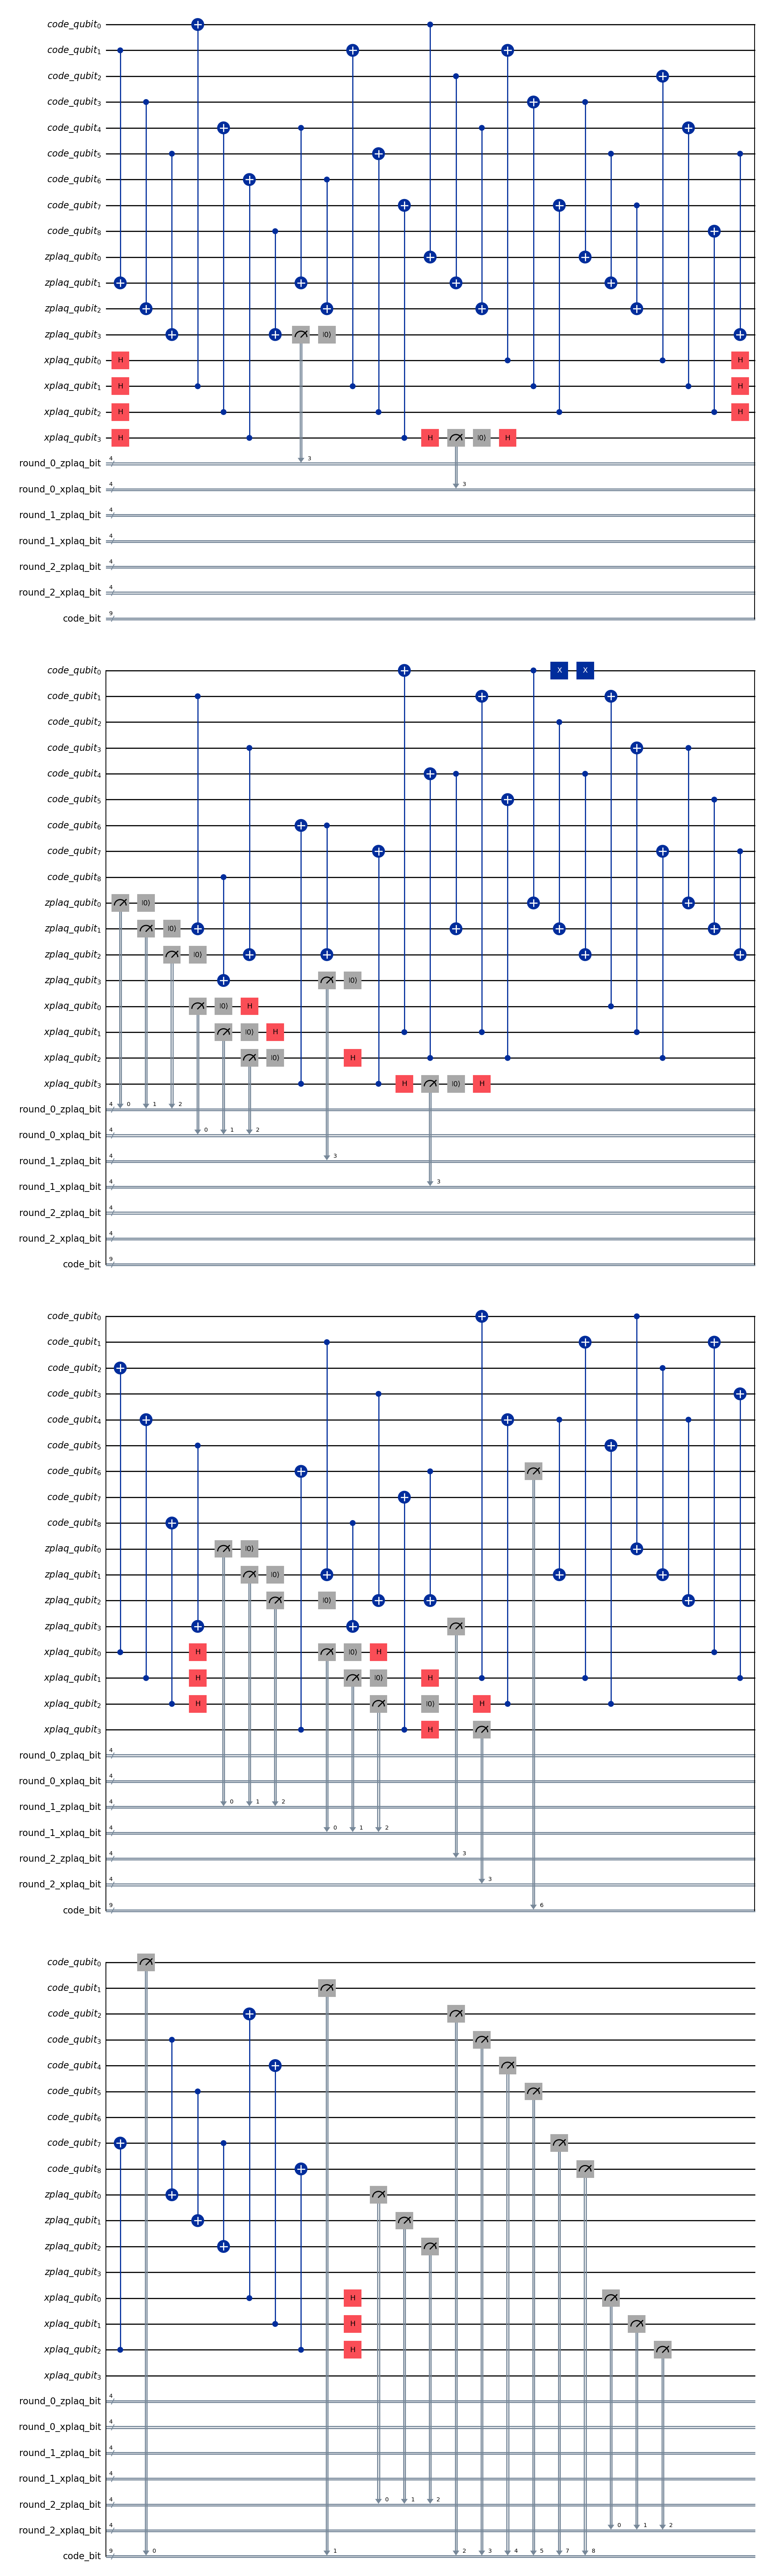

In [6]:
from qiskit_aer import AerSimulator
import qiskit

# 3. Pick target physical qubit index
# (For a d=3 surface code, data qubits are  indices 0 through 8)
target_qubit_index = 0
target_qubit = circuit.qubits[target_qubit_index]

# 4. Create fault gate instruction (an X gate)
fault_instruction = CircuitInstruction(XGate(), (target_qubit,))

# 5. Inject the fault into a specific location in the circuit
insertion_index = 67
circuit.data.insert(insertion_index, fault_instruction)

#--------------------------------------------------------------------------
# 6. Execute the circuit locally using Aer Simulator
simulator = AerSimulator()
compiled_circuit = qiskit.transpile(circuit, simulator) #compiles circuit into simulator-understood assembly
result = simulator.run(compiled_circuit, shots=10000).result()

# 7. Output the syndrome detection result
counts = result.get_counts()
print("Circuit execution successful!")
#print("Syndrome measurement counts:", counts)

# Render a clean, graphical circuit diagram
circuit.draw(output="mpl")

In [4]:
import numpy as np
from bposd import bposd_decoder

# =====================================================================
# 1. CONSTRUCT MATRICES AND INITIALIZE DECODERS (Done once outside loop)
# =====================================================================
Hz_spatial = np.array([
    [1, 0, 0, 1, 0, 0, 0, 0, 0],  # Z0 plaquette touches data qubits 0, 3
    [0, 1, 1, 0, 1, 1, 0, 0, 0],  # Z1 plaquette touches data qubits 1, 2, 4, 5
    [0, 0, 0, 1, 1, 0, 1, 1, 0],  # Z2 plaquette touches data qubits 3, 4, 6, 7
    [0, 0, 0, 0, 1, 1, 0, 1, 1]   # Z3 plaquette touches data qubits 4, 5, 7, 8
], dtype=np.uint8)

Hx_spatial = np.array([
    [0, 1, 1, 0, 0, 0, 0, 0, 0],  # X0 plaquette touches data qubits 1, 2
    [1, 1, 0, 1, 1, 0, 0, 0, 0],  # X1 plaquette touches data qubits 0, 1, 3, 4
    [0, 0, 0, 0, 1, 1, 0, 1, 1],  # X2 plaquette touches data qubits 4, 5, 7, 8
    [0, 0, 0, 0, 0, 0, 1, 1, 0]   # X3 plaquette touches data qubits 6, 7
], dtype=np.uint8)

num_data_qubits = 9
num_plaq = 4
num_rounds = 3

def build_spacetime_decoder(H_spatial):
    """Dynamically scales any 2D spatial matrix into a 3D spacetime matrix decoder."""
    H_spacetime = np.zeros((num_rounds * num_plaq, num_data_qubits + num_rounds * num_plaq), dtype=np.uint8)
    
    for r in range(num_rounds):
        row_start = r * num_plaq
        row_end = row_start + num_plaq
        
        # Map physical data qubits
        H_spacetime[row_start:row_end, :num_data_qubits] = H_spatial
        
        # Map current round sensor links
        meas_col_now = num_data_qubits + r * num_plaq
        H_spacetime[row_start:row_end, meas_col_now:meas_col_now + num_plaq] = np.eye(num_plaq, dtype=np.uint8)
        
        # Map previous round difference links
        if r > 0:
            meas_col_prev = num_data_qubits + (r - 1) * num_plaq
            H_spacetime[row_start:row_end, meas_col_prev:meas_col_prev + num_plaq] = np.eye(num_plaq, dtype=np.uint8)
            
    return bposd_decoder(H_spacetime, error_rate=0.05, max_iter=10, bp_method="product_sum", osd_method="osd_cs", osd_order=0)

# Build two identical decoder instances cleanly
decoder_z = build_spacetime_decoder(Hz_spatial)
decoder_x = build_spacetime_decoder(Hx_spatial)

# =====================================================================
# 2. LOOP OVER THE DICTIONARY COUNTS GENERATED BY THE SIMULATOR
# =====================================================================
# (Assuming 'counts' dictionary is populated by AerSimulator run code)
for sim_output_string, count in counts.items():
    blocks = sim_output_string.split()

    # Extract data qubits (Block 0)
    data_bits = np.array([int(char) for char in blocks[0]], dtype=np.uint8)

    def extract_syndrome(indices):
        """Helper to isolate sub-blocks and calculate temporal defects."""
        r0 = np.array([int(c) for c in blocks[indices[0]]], dtype=np.uint8)
        r1 = np.array([int(c) for c in blocks[indices[1]]], dtype=np.uint8)
        r2 = np.array([int(c) for c in blocks[indices[2]]], dtype=np.uint8)
        return np.concatenate([np.zeros(4, dtype=np.uint8), r1 ^ r0, r2 ^ r1])
    
    # Extract the separate syndrome channels using your block indices
    syndrome_z = extract_syndrome([2, 4, 6])  # Z-plaquettes map to even string blocks
    syndrome_x = extract_syndrome([1, 3, 5])  # X-plaquettes map to odd string blocks
    
    print("\n-------------------------------------------------------------")
    print(f"Processing String: '{sim_output_string}' (Observed {count} times)")
    print(f"Z-Basis Syndrome Input: {syndrome_z}")
    print(f"X-Basis Syndrome Input: {syndrome_x}")

    # Process Z-syndrome (returns X corrections for data qubits and Z-sensor corrections)
    decoder_z.decode(syndrome_z)
    full_correction_z = decoder_z.osdw_decoding
    suggested_x_corrections = full_correction_z[:num_data_qubits]
    suggested_z_meas_corrections = full_correction_z[num_data_qubits:]
    
    # Process X-syndrome (returns Z corrections for data qubits and X-sensor corrections)
    decoder_x.decode(syndrome_x)
    full_correction_x = decoder_x.osdw_decoding
    suggested_z_corrections = full_correction_x[:num_data_qubits]
    suggested_x_meas_corrections = full_correction_x[num_data_qubits:]

    print("\n=== LDPC 3D SPACETIME BP-OSD DECODER RESULTS ===")
    print(f"Suggested X-Gate Data Corrections: {suggested_x_corrections}")
    print(f"Suggested Z-Gate Data Corrections: {suggested_z_corrections}")
    print(f"Z-Measurement Sensor Corrections : {suggested_z_meas_corrections}")
    print(f"X-Measurement Sensor Corrections : {suggested_x_meas_corrections}")



-------------------------------------------------------------
Processing String: '011000001 1111 0001 1111 0000 1111 0000' (Observed 41 times)
Z-Basis Syndrome Input: [0 0 0 0 0 0 0 1 0 0 0 0]
X-Basis Syndrome Input: [0 0 0 0 0 0 0 0 0 0 0 0]

=== LDPC 3D SPACETIME BP-OSD DECODER RESULTS ===
Suggested X-Gate Data Corrections: [0 0 0 0 0 0 0 0 1]
Suggested Z-Gate Data Corrections: [0 0 0 0 0 0 0 0 0]
Z-Measurement Sensor Corrections : [0 0 0 1 0 0 0 1 0 0 0 0]
X-Measurement Sensor Corrections : [0 0 0 0 0 0 0 0 0 0 0 0]

-------------------------------------------------------------
Processing String: '110101010 0111 0001 0111 0000 0111 0000' (Observed 37 times)
Z-Basis Syndrome Input: [0 0 0 0 0 0 0 1 0 0 0 0]
X-Basis Syndrome Input: [0 0 0 0 0 0 0 0 0 0 0 0]

=== LDPC 3D SPACETIME BP-OSD DECODER RESULTS ===
Suggested X-Gate Data Corrections: [0 0 0 0 0 0 0 0 1]
Suggested Z-Gate Data Corrections: [0 0 0 0 0 0 0 0 0]
Z-Measurement Sensor Corrections : [0 0 0 1 0 0 0 1 0 0 0 0]
X-Measure

In [5]:
import stim
from qiskit import qasm2

# 1. Export your actual Qiskit QuantumCircuit to a QASM string
qasm_str = qasm2.dumps(circuit)

# 2. Let Stim parse it directly without third-party converters
print(qasm_str)

OPENQASM 2.0;
include "qelib1.inc";
qreg code_qubit[9];
qreg zplaq_qubit[4];
qreg xplaq_qubit[4];
creg round_0_zplaq_bit[4];
creg round_0_xplaq_bit[4];
creg round_1_zplaq_bit[4];
creg round_1_xplaq_bit[4];
creg round_2_zplaq_bit[4];
creg round_2_xplaq_bit[4];
creg code_bit[9];
h xplaq_qubit[0];
h xplaq_qubit[1];
h xplaq_qubit[2];
h xplaq_qubit[3];
cx code_qubit[1],zplaq_qubit[1];
cx code_qubit[3],zplaq_qubit[2];
cx code_qubit[5],zplaq_qubit[3];
cx xplaq_qubit[1],code_qubit[0];
cx xplaq_qubit[2],code_qubit[4];
cx xplaq_qubit[3],code_qubit[6];
cx code_qubit[4],zplaq_qubit[1];
cx code_qubit[6],zplaq_qubit[2];
cx code_qubit[8],zplaq_qubit[3];
cx xplaq_qubit[1],code_qubit[1];
cx xplaq_qubit[2],code_qubit[5];
cx xplaq_qubit[3],code_qubit[7];
cx code_qubit[0],zplaq_qubit[0];
cx code_qubit[2],zplaq_qubit[1];
cx code_qubit[4],zplaq_qubit[2];
cx xplaq_qubit[0],code_qubit[1];
cx xplaq_qubit[1],code_qubit[3];
cx xplaq_qubit[2],code_qubit[7];
cx code_qubit[3],zplaq_qubit[0];
cx code_qubit[5],zplaq_